# 台北市長選舉 2026｜非民調轉換係數與得票情境模型 v2
**資料截點：2026-10-09｜投票日：2026-11-28**

## TL;DR
- 現有民調、2022/2024 歷史開票、2025 五區罷免、2022 議會席次、2026 施政淨滿意及黃珊珊舊選民交叉資料均已載入。
- **可直接計算**：兩人支持者占比、不同選舉的歷史對數勝算、議會及罷免的描述性對數比率、未表態分流、相對投票參與、條件得票率。
- **沒有辨識的係數**：地方組織、罷免、滿意度變化對市長票的影響。因此它們預設為 0，並提供雙向情境係數及敏感度分析；非因果估計，亦不輸出選舉勝率。
- **防止重複計算**：當期施政滿意、黃珊珊自述舊選民的現況已包含在當期民調；只對其「相對當期改變」另加情境衝擊。


## 1｜資料、分母與可追溯來源
保留原六份民調、原始來源 URL 與 2022 / 2024 / 2025 開票資料。不同選舉與兩人／六人問法不作偽同質處理。

In [1]:
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
AS_OF=pd.Timestamp('2026-10-09')
POLLS = [{'end_date': '2026-05-05', 'field_period': '2026-05-04 ~ 05-05', 'pollster': '新台灣國策智庫／趨勢', 'chiang_pct': 52.9, 'shen_pct': 29.7, 'undecided_pct': 17.4, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': None, 'mode': '待核實', 'question_type': '兩位主要參選人', 'source_level': '媒體轉述發布', 'source': 'https://news.tvbs.com.tw/politics/3197625'}, {'end_date': '2026-05-26', 'field_period': '2026-05-21 ~ 05-26', 'pollster': 'TVBS', 'chiang_pct': 58.0, 'shen_pct': 30.0, 'undecided_pct': 13.0, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': 901, 'mode': '市話 CATI', 'question_type': '兩位主要參選人，有投票意願者', 'source_level': '發布機構新聞', 'source': 'https://news.tvbs.com.tw/politics/3214867'}, {'end_date': '2026-06-22', 'field_period': '2026-06-21 ~ 06-22', 'pollster': '震傳媒／山水', 'chiang_pct': 55.2, 'shen_pct': 27.5, 'undecided_pct': None, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': 1074, 'mode': '市話 CATI', 'question_type': '兩位主要參選人', 'source_level': '發布機構新聞', 'source': 'https://www.zmedia.com.tw/Document/PoolDetail/42781'}, {'end_date': '2026-08-07', 'field_period': '2026-08-05 ~ 08-07', 'pollster': 'TPOC', 'chiang_pct': 48.4, 'shen_pct': 33.0, 'undecided_pct': 18.7, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': 1099, 'mode': '市話訪問（媒體報導）', 'question_type': '兩位主要參選人；其餘為無法選出任一候選人', 'source_level': '媒體轉述發布', 'source': 'https://news.tvbs.com.tw/politics/4007563'}, {'end_date': '2026-09-18', 'field_period': '2026-09-16 ~ 09-18', 'pollster': '信民／畢肯', 'chiang_pct': 41.7, 'shen_pct': 40.5, 'undecided_pct': 10.6, 'minor_pct': 2.1, 'no_vote_pct': 5.2, 'sample_n': 1076, 'mode': '市話752＋手機324 CATI', 'question_type': '六位登記參選者、含不投票／廢票', 'source_level': '調查方法與題目公開', 'source': 'https://news.tvbs.com.tw/politics/4025675'}, {'end_date': '2026-10-07', 'field_period': '2026-10-03, 10-05 ~ 10-07', 'pollster': 'TVBS', 'chiang_pct': 49.0, 'shen_pct': 41.0, 'undecided_pct': 11.0, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': 1120, 'mode': '市話 CATI', 'question_type': '兩位主要參選人，有投票意願者', 'source_level': '發布機構新聞', 'source': 'https://news.tvbs.com.tw/politics/4033527'}]
CONTEXT = [{'year': 2022, 'type': '市長選舉', 'metric': '蔣萬安得票', 'value': 575590, 'unit': '票', 'basis': '台北市', 'use': '歷史背景，不當成2026票數', 'source': 'https://www.cna.com.tw/news/aipl/202211260299.aspx'}, {'year': 2022, 'type': '市長選舉', 'metric': '陳時中得票', 'value': 434558, 'unit': '票', 'basis': '台北市', 'use': '歷史背景，不當成2026票數', 'source': 'https://www.cna.com.tw/news/aipl/202211260299.aspx'}, {'year': 2022, 'type': '市長選舉', 'metric': '黃珊珊得票', 'value': 342141, 'unit': '票', 'basis': '台北市', 'use': '不同於2026自述投黃者', 'source': 'https://www.cna.com.tw/news/aipl/202211260299.aspx'}, {'year': 2022, 'type': '市長選舉', 'metric': '有效票', 'value': 1360951, 'unit': '票', 'basis': '台北市', 'use': '票數正規化', 'source': 'https://election.ltn.com.tw/2022/realtime'}, {'year': 2022, 'type': '市長選舉', 'metric': '投票率', 'value': 67.7, 'unit': '%', 'basis': '台北市', 'use': '歷史參考', 'source': 'https://www.cna.com.tw/news/aipl/202211260299.aspx'}, {'year': 2024, 'type': '總統選舉', 'metric': '侯友宜得票', 'value': 587258, 'unit': '票', 'basis': '台北市', 'use': '不同選舉，不直接轉成市長票', 'source': 'https://govtw.org/election/2024-P'}, {'year': 2024, 'type': '總統選舉', 'metric': '賴清德得票', 'value': 587899, 'unit': '票', 'basis': '台北市', 'use': '不同選舉，不直接轉成市長票', 'source': 'https://govtw.org/election/2024-P'}, {'year': 2024, 'type': '總統選舉', 'metric': '柯文哲得票', 'value': 366854, 'unit': '票', 'basis': '台北市', 'use': '不同選舉，不直接轉成市長票', 'source': 'https://govtw.org/election/2024-P'}, {'year': 2024, 'type': '總統選舉', 'metric': '投票率', 'value': 74.28, 'unit': '%', 'basis': '台北市', 'use': '歷史參考', 'source': 'https://govtw.org/election/2024-P'}, {'year': 2022, 'type': '議員選舉', 'metric': '國民黨席次', 'value': 30, 'unit': '席', 'basis': '台北市61席', 'use': '議會代表性，不能換算成市長票', 'source': 'https://www.cna.com.tw/news/aipl/202211260304.aspx'}, {'year': 2022, 'type': '議員選舉', 'metric': '民進黨席次', 'value': 21, 'unit': '席', 'basis': '台北市61席', 'use': '議會代表性，不能換算成市長票', 'source': 'https://www.cna.com.tw/news/aipl/202211260304.aspx'}, {'year': 2022, 'type': '議員選舉', 'metric': '民眾黨席次', 'value': 4, 'unit': '席', 'basis': '台北市61席', 'use': '議會代表性，不能換算成市長票', 'source': 'https://www.cna.com.tw/news/aipl/202211260304.aspx'}, {'year': 2022, 'type': '議員選舉', 'metric': '其他席次', 'value': 6, 'unit': '席', 'basis': '台北市61席', 'use': '議會代表性，不能換算成市長票', 'source': 'https://www.cna.com.tw/news/aipl/202211260304.aspx'}, {'year': 2025, 'type': '五席立委罷免', 'metric': '同意罷免合計', 'value': 330340, 'unit': '票', 'basis': '五選區，非全市', 'use': '只作動員背景，不轉換支持票', 'source': 'https://www.cna.com.tw/news/aipl/202507260215.aspx'}, {'year': 2025, 'type': '五席立委罷免', 'metric': '不同意罷免合計', 'value': 428596, 'unit': '票', 'basis': '五選區，非全市', 'use': '只作動員背景，不轉換支持票', 'source': 'https://www.cna.com.tw/news/aipl/202507260215.aspx'}, {'year': 2025, 'type': '五席立委罷免', 'metric': '投票率', 'value': 59.03, 'unit': '%', 'basis': '五選區合計', 'use': '不能解讀成全市投票率', 'source': 'https://www.cna.com.tw/news/aipl/202507260215.aspx'}, {'year': 2026, 'type': '施政評價', 'metric': '10月現任市長滿意', 'value': 52.0, 'unit': '%', 'basis': 'TVBS 10月調查', 'use': '獨立測量指標，未建立選票轉換率', 'source': 'https://news.tvbs.com.tw/politics/4033530'}, {'year': 2026, 'type': '施政評價', 'metric': '10月現任市長不滿意', 'value': 35.0, 'unit': '%', 'basis': 'TVBS 10月調查', 'use': '獨立測量指標，未建立選票轉換率', 'source': 'https://news.tvbs.com.tw/politics/4033530'}, {'year': 2026, 'type': '歷史選票自述交叉表', 'metric': '10月自述2022投黃珊珊者轉支持沈', 'value': 53.0, 'unit': '%', 'basis': 'TVBS 10月，2022自述投黃者', 'use': '不可直接乘2022全部實際黃珊珊票', 'source': 'https://news.tvbs.com.tw/politics/4033530'}, {'year': 2026, 'type': '歷史選票自述交叉表', 'metric': '10月自述2022投黃珊珊者轉支持蔣', 'value': 39.0, 'unit': '%', 'basis': 'TVBS 10月，2022自述投黃者', 'use': '不可直接乘2022全部實際黃珊珊票', 'source': 'https://news.tvbs.com.tw/politics/4033530'}, {'year': 2026, 'type': '問卷投票意願', 'metric': '10月表示會投票', 'value': 92.0, 'unit': '%', 'basis': 'TVBS 10月，表示一定或可能投票', 'use': '自述意願非實際投票率', 'source': 'https://news.tvbs.com.tw/politics/4033527'}, {'year': 2026, 'type': '機構推估', 'metric': 'TVBS 預估投票率', 'value': 71.0, 'unit': '%', 'basis': 'TVBS推估，不是觀測結果', 'use': '僅作情境參數候選', 'source': 'https://news.tvbs.com.tw/politics/4033527'}]
RECALL = [{'district': '王鴻薇（第三選區）', 'yes': 76463, 'no': 86311}, {'district': '李彥秀（第四選區）', 'yes': 78560, 'no': 105169}, {'district': '羅智強（第六選區）', 'yes': 56726, 'no': 74808}, {'district': '徐巧芯（第七選區）', 'yes': 62633, 'no': 75401}, {'district': '賴士葆（第八選區）', 'yes': 55958, 'no': 86907}]
polls=pd.DataFrame(POLLS)
context=pd.DataFrame(CONTEXT)
recall=pd.DataFrame(RECALL)
polls['end_date']=pd.to_datetime(polls['end_date'])
polls['pair_chiang_share_pct']=100*polls['chiang_pct']/(polls['chiang_pct']+polls['shen_pct'])
display(polls[['end_date','pollster','chiang_pct','shen_pct','undecided_pct','minor_pct','no_vote_pct','sample_n','mode','question_type','source']])

,end_date,pollster,chiang_pct,shen_pct,undecided_pct,minor_pct,no_vote_pct,sample_n,mode,question_type,source
0,2026-05-05,新台灣國策智庫／趨勢,52.9,29.7,17.4,NaN,NaN,NaN,待核實,兩位主要參選人,https://news.tvbs.com.tw/politics/3197625
1,2026-05-26,TVBS,58.0,30.0,13.0,NaN,NaN,901.0,市話 CATI,兩位主要參選人，有投票意願者,https://news.tvbs.com.tw/politics/3214867
2,2026-06-22,震傳媒／山水,55.2,27.5,NaN,NaN,NaN,1074.0,市話 CATI,兩位主要參選人,https://www.zmedia.com.tw/Document/PoolDetail/...
3,2026-08-07,TPOC,48.4,33.0,18.7,NaN,NaN,1099.0,市話訪問（媒體報導）,兩位主要參選人；其餘為無法選出任一候選人,https://news.tvbs.com.tw/politics/4007563
4,2026-09-18,信民／畢肯,41.7,40.5,10.6,2.1,5.2,1076.0,市話752＋手機324 CATI,六位登記參選者、含不投票／廢票,https://news.tvbs.com.tw/politics/4025675
5,2026-10-07,TVBS,49.0,41.0,11.0,NaN,NaN,1120.0,市話 CATI,兩位主要參選人，有投票意願者,https://news.tvbs.com.tw/politics/4033527


## 2｜已量測量與反事實係數的分界

| 因素 | 已量測的指標 | 如何進模型 | 係數辨識狀態 |
|---|---|---|---|
| 歷史票源 | 2022蔣/陳及2024侯/賴兩人票數 | 歷史對數勝算與當期民調按 `historical_blend` 融合 | 基準可重算；融合率未校準 |
| 議會組織 | 國民黨30席、民進黨21席 | `k_council × ln(30/21)` | 係數尚未識別，預設0 |
| 五區罷免 | 不同意428596、同意330340 | `k_recall × ln(428596/330340)` | 只有五區；不可認定不同意=蔣票；係數雙向、預設0 |
| 施政評價 | 10月滿意52%、不滿意35%，淨17點 | `k_approval × (未來淨滿意相對17點的變動/10)` | 當期差異已在民調內，變動情境預設0 |
| 黃珊珊舊選民 | 10月自述投黃者占比約15%，蔣39%、沈53% | 僅模擬群體內之後發生的蔣/沈票轉移 `群體占比 × 移轉百分點` | 非實際2022選票追蹤；當期資料不可重複加分 |
| 動員 | 2022地方67.7%、2024總統74.28% | 兩邊有效支持乘可調參與係數 | 總投票率無法識別兩邊相對係數 |

**解釋規則**：沒有實證支持的係數預設0；非零設定代表「假設若存在某種轉換力道，條件票率會如何」，不是估計出誰當選。

In [2]:
"""2026台北市長：可重算條件得票情境模型（不產出勝率）。
每個參數只代表使用者設定的反事實假設，除歷史票數以外未做因果校準。
"""
from math import exp,log
from datetime import date
import csv
from pathlib import Path

SOURCE_DATE = date(2026,10,9)
POLL_INPUTS = {
 'TVBS 10月': dict(chiang=49.,shen=41.,undecided=11.,minor=0.,excluded=0.,kind='兩人對比／沒有其他參選者的分母'),
 '信民 9月':dict(chiang=41.7,shen=40.5,undecided=10.6,minor=2.1,excluded=5.2,kind='六人題目／不投票及廢票自有效票排除'),
}
HISTORY = {
 '2022 市長兩人':(575590.,434558.),
 '2024 總統藍綠':(587258.,587899.),
}
CONTEXT = {
 'council_log_ratio': log(30./21.),
 'recall_log_ratio': log(428596./330340.),
 'approval_net_reference': 52.-35.,
 'self_report_huang_share_pct':15.,
 'self_report_huang_chiang_pct':39.,
 'self_report_huang_shen_pct':53.,
}
DEFAULTS=dict(undecided_to_shen=50.,historical_blend=0.,history_base='2024 總統藍綠',
              council_log_weight=0.,recall_log_weight=0.,approval_delta_net=0.,approval_log_weight=0.,
              cohort_shift=0.,cohort_share=15.,turnout_ratio_c=1.,turnout_ratio_s=1.,minor_ratio=1.)
BOUNDS=dict(undecided_to_shen=(0,100),historical_blend=(0,.35),
            council_log_weight=(-.25,.25),recall_log_weight=(-.25,.25),
            approval_delta_net=(-20,20),approval_log_weight=(-.2,.2),
            cohort_shift=(-20,20),cohort_share=(0,25),
            turnout_ratio_c=(.8,1.2),turnout_ratio_s=(.8,1.2),minor_ratio=(.8,1.2))
def logistic(z):
    if z>=0: return 1/(1+exp(-z))
    u=exp(z);return u/(1+u)
def logit(p):
    if not 0<p<1:raise ValueError('logit only accepts a probability strictly between zero and one')
    return log(p/(1-p))
def run_model(poll='TVBS 10月',**updates):
    if poll not in POLL_INPUTS:raise KeyError('unknown poll baseline')
    a=DEFAULTS.copy();a.update(updates)
    for k,(lo,hi) in BOUNDS.items():
        if not lo<=a[k]<=hi:raise ValueError(f'{k} outside [{lo},{hi}]')
    if a['history_base'] not in HISTORY:raise ValueError('unknown historical comparison')
    b=POLL_INPUTS[poll]
    raw_c=b['chiang']+b['undecided']*(1-a['undecided_to_shen']/100)
    raw_s=b['shen']+b['undecided']*a['undecided_to_shen']/100
    # 只對「自述2022投黃者」在當期問卷之後的 *變化* 建模，不把舊票絕對分布重算一次
    cohort_points=(a['cohort_share']/100.)*a['cohort_shift']
    raw_c+=cohort_points;raw_s-=cohort_points
    if min(raw_c,raw_s)<=0:raise ValueError('cohort input exceeded ballot mass')
    pair_total=raw_c+raw_s
    p0=raw_c/pair_total
    h_c,h_s=HISTORY[a['history_base']]
    h_p=h_c/(h_c+h_s)
    # 資料本身可重算的 log-odds 差；融合係數本身為可調敏感度假設，非估計出的因果效應。
    history_term=a['historical_blend']*(logit(h_p)-logit(p0))
    organization_term=a['council_log_weight']*CONTEXT['council_log_ratio']
    recall_term=a['recall_log_weight']*CONTEXT['recall_log_ratio']
    approval_term=a['approval_log_weight']*(a['approval_delta_net']/10.)
    terms=dict(history=history_term,council=organization_term,recall=recall_term,approval_change=approval_term)
    logits=logit(p0)+sum(terms.values())
    cc=pair_total*logistic(logits)*a['turnout_ratio_c']
    ss=pair_total*(1-logistic(logits))*a['turnout_ratio_s']
    mm=b['minor']*a['minor_ratio']
    d=cc+ss+mm
    return dict(poll=poll,chiang_pct=100*cc/d,shen_pct=100*ss/d,
                other_pct=100*mm/d,source_pair_pct=100*p0,
                base_major_pair_pct=100*b['chiang']/(b['chiang']+b['shen']),
                raw_mass=dict(chiang=raw_c,shen=raw_s,minor=b['minor'],excluded=b['excluded']),
                context=dict(CONTEXT),terms_logodds=terms,
                total_logodds_shift=sum(terms.values()),
                parameters=a,denominator=d,
                note='conditional counterfactual, not an observed result or probabilistic forecast')


### 核心式（兩人比率調整）

先將民調與未表態票調整為 `C`、`S`，再以

\[
\operatorname{logit}(p^*)=\operatorname{logit}\left(rac{C}{C+S}ight)+
\lambda_H(\operatorname{logit}(p_H)-\operatorname{logit}(p))+
eta_O\lnrac{30}{21}+eta_R\lnrac{428596}{330340}+
eta_Arac{\Delta A}{10}
\]

條件票率最後再乘各方參與係數並重新正規化；六人調查保留其他候選人占比。\(\lambda_H,eta_O,eta_R,eta_A\)皆為**可調情境係數**，不是由當前有限資料識別出的因果係數。

## 3｜資料一致性檢查、歷史尺度

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
assert len(polls)==6
assert len(context)>=20
assert int(recall['yes'].sum())==330340
assert int(recall['no'].sum())==428596
assert sum([30,21,4,6])==61
assert sum([587899,587258,366854])==1542011
assert abs(CONTEXT['approval_net_reference']-17)<1e-8
for key in POLL_INPUTS:
 r=run_model(key)
 assert abs(r['chiang_pct']+r['shen_pct']+r['other_pct']-100)<1e-8
 print(key, {k:round(r[k],4) for k in ['chiang_pct','shen_pct','other_pct']})
print('議會描述性 ln 比率:',round(CONTEXT['council_log_ratio'],4))
print('五區罷免描述性 ln 比率:',round(CONTEXT['recall_log_ratio'],4))
for name,(c,s) in HISTORY.items():
 print(name,'兩人對比占比',round(100*c/(c+s),3),'%')


TVBS 10月 {'chiang_pct': 53.9604, 'shen_pct': 46.0396, 'other_pct': 0.0}
信民 9月 {'chiang_pct': 49.5258, 'shen_pct': 48.2613, 'other_pct': 2.2129}
議會描述性 ln 比率: 0.3567
五區罷免描述性 ln 比率: 0.2604
2022 市長兩人 兩人對比占比 56.981 %
2024 總統藍綠 兩人對比占比 49.973 %


## 4｜情境組合，兩個民調基準分開顯示

In [4]:
SCENARIOS = {
 '當期觀察基準，全部外加係數0':{},
 '歷史2022融合15%': {'historical_blend':.15,'history_base':'2022 市長兩人'},
 '歷史2024融合15%': {'historical_blend':.15,'history_base':'2024 總統藍綠'},
 '組織與罷免正向係數': {'council_log_weight':.15,'recall_log_weight':.15},
 '組織與罷免反向係數': {'council_log_weight':-.15,'recall_log_weight':-.15},
 '淨滿意增加10點(傳導.1)': {'approval_delta_net':10,'approval_log_weight':.1},
 '舊黃選民蔣方淨增10點': {'cohort_shift':10},
 '舊黃選民沈方淨增10點': {'cohort_shift':-10},
 '蔣方相對參與95%': {'turnout_ratio_c':.95},
 '沈方相對參與95%': {'turnout_ratio_s':.95},
}
records=[]
for poll in POLL_INPUTS:
 for label,args in SCENARIOS.items():
  r=run_model(poll,**args)
  records.append({'基準':poll,'情境':label,'蔣條件得票率':r['chiang_pct'],'沈條件得票率':r['shen_pct'],'其他':r['other_pct']})
sc=pd.DataFrame(records)
display(sc.round(2))


,基準,情境,蔣條件得票率,沈條件得票率,其他
0,TVBS 10月,當期觀察基準，全部外加係數0,53.96,46.04,0.00
1,TVBS 10月,歷史2022融合15%,54.42,45.58,0.00
2,TVBS 10月,歷史2024融合15%,53.36,46.64,0.00
3,TVBS 10月,組織與罷免正向係數,56.25,43.75,0.00
4,TVBS 10月,組織與罷免反向係數,51.65,48.35,0.00
5,TVBS 10月,淨滿意增加10點(傳導.1),56.43,43.57,0.00
6,TVBS 10月,舊黃選民蔣方淨增10點,55.45,44.55,0.00
7,TVBS 10月,舊黃選民沈方淨增10點,52.48,47.52,0.00
8,TVBS 10月,蔣方相對參與95%,52.68,47.32,0.00
9,TVBS 10月,沈方相對參與95%,55.23,44.77,0.00


## 5｜係數敏感度：每個因子單獨變動，其餘固定

In [5]:
def factor_sensitivity(poll='TVBS 10月'):
 specs={
  '議會轉換係數':('council_log_weight',[-.25,-.15,0,.15,.25]),
  '罷免轉換係數':('recall_log_weight',[-.25,-.15,0,.15,.25]),
  '歷史融合率(2022)':('historical_blend',[0,.05,.1,.2,.35]),
  '淨滿意變動(係數.10)':('approval_delta_net',[-20,-10,0,10,20]),
  '舊黃選民支持轉移':('cohort_shift',[-20,-10,0,10,20]),
 }
 rows=[]
 for label,(key,values) in specs.items():
  for value in values:
   kwargs={key:value}
   if key=='historical_blend':kwargs['history_base']='2022 市長兩人'
   if key=='approval_delta_net':kwargs['approval_log_weight']=.1
   o=run_model(poll,**kwargs)
   rows.append({'factor':label,'value':value,'chiang':o['chiang_pct'],'shen':o['shen_pct'],'other':o['other_pct']})
 return pd.DataFrame(rows)
sens=factor_sensitivity()
display(sens.round(3))


,factor,value,chiang,shen,other
0,議會轉換係數,-0.25,51.739,48.261,0.0
1,議會轉換係數,-0.15,52.629,47.371,0.0
2,議會轉換係數,0.00,53.960,46.040,0.0
3,議會轉換係數,0.15,55.286,44.714,0.0
4,議會轉換係數,0.25,56.166,43.834,0.0
5,罷免轉換係數,-0.25,52.340,47.660,0.0
6,罷免轉換係數,-0.15,52.989,47.011,0.0
7,罷免轉換係數,0.00,53.960,46.040,0.0
8,罷免轉換係數,0.15,54.929,45.071,0.0
9,罷免轉換係數,0.25,55.573,44.427,0.0


/tmp/ipykernel_1009/560964267.py:6: UserWarning: Glyph 27511 (\N{CJK UNIFIED IDEOGRAPH-6B77}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/560964267.py:6: UserWarning: Glyph 21490 (\N{CJK UNIFIED IDEOGRAPH-53F2}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/560964267.py:6: UserWarning: Glyph 34701 (\N{CJK UNIFIED IDEOGRAPH-878D}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/560964267.py:6: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/560964267.py:6: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()


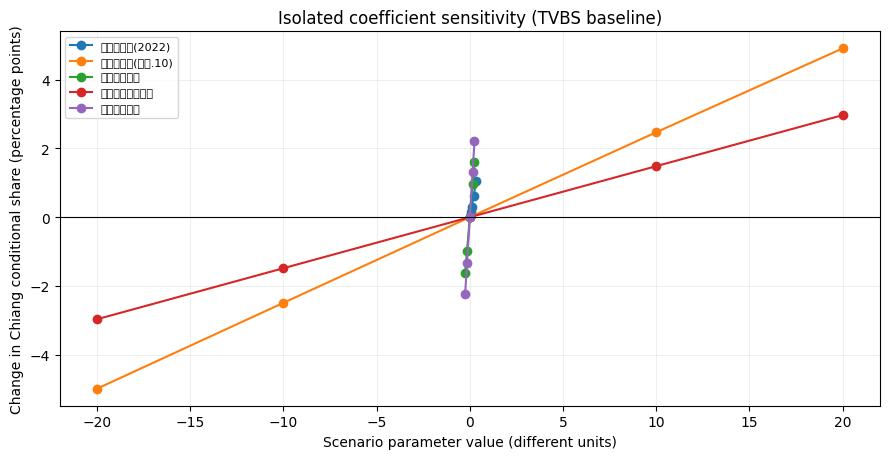

In [6]:
fig,ax=plt.subplots(figsize=(9,4.7))
for f,grp in sens.groupby('factor'):
 ax.plot(grp['value'],grp['chiang']-run_model('TVBS 10月')['chiang_pct'],marker='o',label=f)
ax.axhline(0,color='black',linewidth=.8)
ax.set(title='Isolated coefficient sensitivity (TVBS baseline)',xlabel='Scenario parameter value (different units)',ylabel='Change in Chiang conditional share (percentage points)')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()


## 6｜重要交互作用：多因子同時變動

In [7]:
joint_cases={
 '觀察基準':{},
 '組合A（假設組）':dict(historical_blend=.15,history_base='2022 市長兩人',council_log_weight=.15,recall_log_weight=.1,approval_delta_net=5,approval_log_weight=.08,cohort_shift=5,turnout_ratio_c=1.02),
 '組合B（假設組）':dict(historical_blend=.15,history_base='2024 總統藍綠',council_log_weight=-.15,recall_log_weight=-.1,approval_delta_net=-5,approval_log_weight=.08,cohort_shift=-5,turnout_ratio_s=1.02),
}
rows=[]
for name,kw in joint_cases.items():
 for poll in POLL_INPUTS:
  r=run_model(poll,**kw)
  rows.append({'case':name,'poll':poll,'chiang':r['chiang_pct'],'shen':r['shen_pct'],'other':r['other_pct']})
joint=pd.DataFrame(rows);display(joint.round(3))


,case,poll,chiang,shen,other
0,觀察基準,TVBS 10月,53.960,46.040,0.000
1,觀察基準,信民 9月,49.526,48.261,2.213
2,組合A（假設組）,TVBS 10月,58.465,41.535,0.000
3,組合A（假設組）,信民 9月,54.528,43.282,2.189
4,組合B（假設組）,TVBS 10月,49.251,50.749,0.000
5,組合B（假設組）,信民 9月,45.365,52.444,2.190


/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 35264 (\N{CJK UNIFIED IDEOGRAPH-89C0}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 23519 (\N{CJK UNIFIED IDEOGRAPH-5BDF}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH-6E96}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 32068 (\N{CJK UNIFIED IDEOGRAPH-7D44}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()


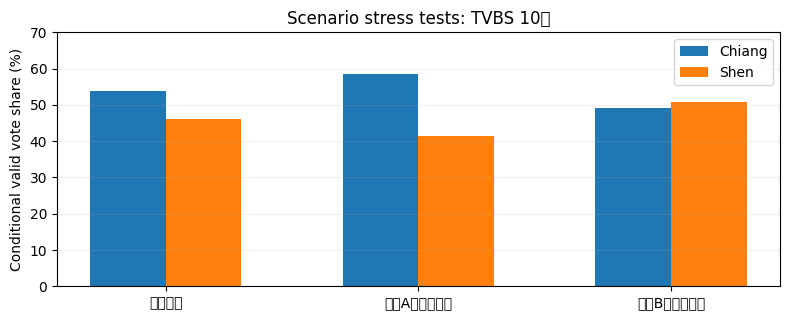

/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 35264 (\N{CJK UNIFIED IDEOGRAPH-89C0}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 23519 (\N{CJK UNIFIED IDEOGRAPH-5BDF}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 28310 (\N{CJK UNIFIED IDEOGRAPH-6E96}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 32068 (\N{CJK UNIFIED IDEOGRAPH-7D44}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()


/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 20449 (\N{CJK UNIFIED IDEOGRAPH-4FE1}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 27665 (\N{CJK UNIFIED IDEOGRAPH-6C11}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/tmp/ipykernel_1009/3853766665.py:6: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) DejaVu Sans.
  ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20449 (\N{CJK UNIFIED IDEOGRAPH-4FE1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27665 (\N{CJK UNIFIED IDEOGRAPH-6C11}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(by

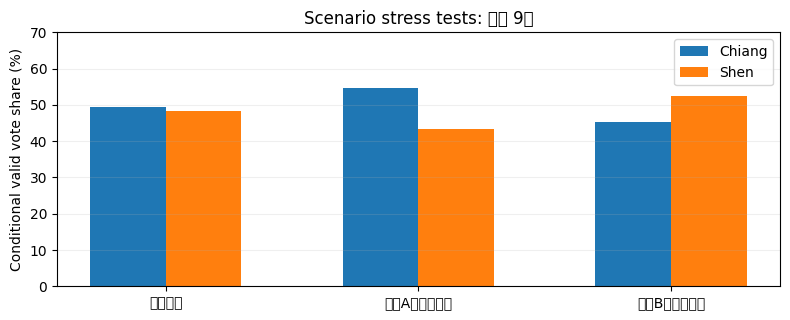

In [8]:
for poll,group in joint.groupby('poll'):
 fig,ax=plt.subplots(figsize=(8,3.3))
 labels=group['case'].tolist();x=np.arange(len(labels));width=.30
 ax.bar(x-width/2,group['chiang'],width,label='Chiang');ax.bar(x+width/2,group['shen'],width,label='Shen')
 ax.set_xticks(x,labels);ax.set(ylabel='Conditional valid vote share (%)',title=f'Scenario stress tests: {poll}',ylim=(0,70))
 ax.legend();ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()


## 7｜完整邊界測試與方法限制

In [9]:
import itertools
for p in POLL_INPUTS:
 for u,cohort,hb,org,rec,ta,tb in itertools.product([0,50,100],[-20,0,20],[0,.35],[-.25,.25],[-.25,.25],[.8,1.2],[.8,1.2]):
  z=run_model(p,undecided_to_shen=u,cohort_shift=cohort,historical_blend=hb,council_log_weight=org,recall_log_weight=rec,turnout_ratio_c=ta,turnout_ratio_s=tb)
  assert 0<=min(z['chiang_pct'],z['shen_pct'],z['other_pct'])
  assert abs(z['chiang_pct']+z['shen_pct']+z['other_pct']-100)<1e-9
print('PASS: all boundary combinations and vote-share normalisation.')
assert run_model('TVBS 10月')['other_pct']==0
assert run_model('信民 9月')['other_pct']>0
for p in POLL_INPUTS:
 assert run_model(p,historical_blend=0,council_log_weight=0,recall_log_weight=0,approval_delta_net=0,cohort_shift=0)['chiang_pct']==run_model(p)['chiang_pct']
print('PASS: no incremental shock at survey baseline; poll denominator preserved.')


PASS: all boundary combinations and vote-share normalisation.
PASS: no incremental shock at survey baseline; poll denominator preserved.


## 8｜結果閱讀與稽核指南

1. **觀察**：六份民調與官方開票資料是輸入，並非模型預測。
2. **算術換算**：`ln(30/21)`、`ln(不同意/同意)`、2022/2024兩人票率是依觀察可精確重算的中間變數。
3. **情境係數**：`council_log_weight`、`recall_log_weight`、`approval_log_weight` 等目前缺少跨選舉配對資料，**無法單靠此次資料估計因果效果**。非零結果應讀作條件結果。
4. **代表性**：2025 罷免僅五選區、2022 市長與2024 總統屬不同類型、兩人題目無法映射六人開票。
5. **雙重計數**：已發生施政與舊票源分布通常已影響當期民調，所以只允許輸入「相對調查時點的變化」。
6. **實際校準所缺**：完整各區歷次選舉配對資料、同時點跨年民調、地方志工/財務可比資料、施政變化與支持度的縱向設計。

**輸出為具明確前提的得票敏感度模型，不提供特定候選人的主觀勝率。**
